# C0 · how much of the ISBI error is annotation noise? (free analysis 5)

**Why.** On ISBI the target accounted for only a few percent of the baseline error variance, so target shaping could change little.
On clean synthetic images with exact labels it accounted for about half, and transfer was strong. One candidate for the large
"untouchable" part of the ISBI error is the ground truth itself: it is the mean of two doctors' clicks, so it carries their noise,
and an error measured against a noisy ground truth contains that noise whatever the network does.

**Method (no training).**
* For every image and landmark, d = senior − junior (mm). If the two annotators' errors are independent, the noise of their mean
  (the ground truth) has covariance Σ_GT = Cov(d) / 4. The mean of d is a systematic offset between the annotators, reported
  separately; it shifts the ground truth but adds no scatter. Correlated annotator errors (both wrong the same way) are invisible
  here, so Σ_GT is a lower bound on the label noise.
* The baseline error of each tier (round B0 runs at σ₀: High `w1.00`, Medium `w1.41`, seeds 1–3; primary decoder; 250 test images;
  gross failures > 4 mm removed; each run centred on its own mean) is projected on the tier's frozen baseline axes u (major) and v.
* Shares of the baseline error variance along each axis: **label noise** Σ_GT,d / SD_B0,d²; **target term** k σ₀² / SD_B0,d² with the
  tier's k from the additive-variance analysis; **rest** (image ambiguity and the network) = 1 − both.
* **Primary estimate: robust.** SDs are sensitive to a few gross annotator disagreements and to gross model errors, so the primary
  shares use 1.4826 × MAD of the projections (annotator difference / 2 for the ground truth; per-run median-centred errors for the
  model, without the 4 mm cut: MAD needs none, and the cut would truncate broad landmarks such as soft-tissue pogonion while the
  annotator differences stay uncut). The plain-SD shares are a sensitivity check; they come out higher, because of a few large
  disagreements.
* Also: is the label noise itself elongated, and along the error's axis?

Status: exploratory, descriptive. The test-set ground-truth noise is what an error measured against the ground truth cannot get
below; training-label noise may add more error on top and is not separated here.

In [1]:
ANALYSIS = "annotation_noise"
import os, json, math, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def _repo_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "weights").is_dir() and (q / "data").is_dir():
            return q
    return None

_REPO = _repo_root()
W_ROOT = Path(os.environ.get("C0_WEIGHTS", "/tf/weights/C0" if os.path.isdir("/tf/weights/C0") else str(_REPO / "weights" / "C0")))
DATA_ROOT = Path(os.environ.get("ISBI_ROOT", "/tf/data/ISBI2015" if os.path.isdir("/tf/data/ISBI2015") else str(_REPO / "data" / "ISBI2015")))
OUT = W_ROOT / "analyses" / ANALYSIS
OUT.mkdir(parents=True, exist_ok=True)
K, PIXEL_MM, MM_PER_PX, GROSS_MM, PD = 19, 0.1, 0.3125, 4.0, "quadratic"
TEST_IDS = list(range(151, 401))
TIERS = {"High": {"sigma0_px": 5.0, "b0": [f"C0_ISBI2015_High_R_w1.00_s{s}" for s in (1, 2, 3)]},
         "Medium": {"sigma0_px": 5.0 * 2 ** 0.5, "b0": [f"C0_ISBI2015_Medium_R_w1.41_s{s}" for s in (1, 2, 3)]}}
COLORS = {"High": "#0072B2", "Medium": "#D55E00"}
NAMES = pd.read_csv(W_ROOT / "ISBI2015_High" / "arm_A_summary" / "alpha_by_landmark.csv").set_index("landmark").name

def read_annotation(p):
    pts = []
    for line in Path(p).read_text(errors="ignore").splitlines():
        nums = re.findall(r"-?\d+(?:\.\d+)?", line)
        if len(nums) >= 2:
            pts.append((float(nums[0]), float(nums[1])))
        if len(pts) == K:
            break
    assert len(pts) == K, f"{p}: {len(pts)} coordinate lines"
    return np.array(pts)

ANN = {"senior": {}, "junior": {}}
for p in DATA_ROOT.rglob("*.txt"):
    if p.stem.isdigit():
        who = "senior" if "senior" in str(p.parent).lower() else "junior" if "junior" in str(p.parent).lower() else None
        if who:
            ANN[who][int(p.stem)] = read_annotation(p)
assert all(set(range(1, 401)) <= set(ANN[w]) for w in ANN), "annotations missing"
rows = []
for i in range(1, 401):
    s, j = ANN["senior"][i], ANN["junior"][i]
    for k in range(K):
        rows.append({"image_id": i, "landmark": k + 1, "subset": "train" if i <= 150 else "test",
                     "dx_mm": (s[k, 0] - j[k, 0]) * PIXEL_MM, "dy_mm": (s[k, 1] - j[k, 1]) * PIXEL_MM})
DIFF = pd.DataFrame(rows)
DIFF["r_mm"] = np.hypot(DIFF.dx_mm, DIFF.dy_mm)
print("annotation pairs:", len(DIFF), "| median senior-junior distance on the test images (mm):",
      round(DIFF[DIFF.subset == "test"].r_mm.median(), 3))

annotation pairs: 7600 | median senior-junior distance on the test images (mm): 1.414


## 1. Ground-truth noise per landmark and its projection on each tier's baseline axes

In [2]:
def axes_of(C):
    ev, V = np.linalg.eigh(C)
    return (math.degrees(math.atan2(V[1, 1], V[0, 1])) + 90) % 180 - 90, math.sqrt(ev[1] / ev[0]) if ev[0] > 0 else np.nan

def proj_var(C, ang_deg):
    a = math.radians(ang_deg)
    u, v = np.array([math.cos(a), math.sin(a)]), np.array([-math.sin(a), math.cos(a)])
    return float(u @ C @ u), float(v @ C @ v)

MAD = lambda x: 1.4826 * np.median(np.abs(x - np.median(x)))

def unit(ang_deg):
    a = math.radians(ang_deg)
    return np.array([math.cos(a), math.sin(a)]), np.array([-math.sin(a), math.cos(a)])

def err_cov(df):
    e = np.concatenate([np.stack([h.dx_mm - h.dx_mm.mean(), h.dy_mm - h.dy_mm.mean()], 1) for _, h in df.groupby("run_id")])
    return np.cov(e.T)

K_ADD = json.loads((W_ROOT / "analyses" / "additive_variance" / "additive_model_k.json").read_text())
rows = []
for t, cfg in TIERS.items():
    axes = pd.read_csv(W_ROOT / f"ISBI2015_{t}" / "arm_R_summary" / f"baseline_axes_ISBI2015_{t}.csv").set_index("landmark")
    pred = []
    for rid in cfg["b0"]:
        p = pd.read_csv(W_ROOT / f"ISBI2015_{t}" / rid / "predictions_test.csv.gz")
        pred.append(p[(p.checkpoint == "final") & (p.decoder == PD)].assign(run_id=rid))
    pred = pd.concat(pred, ignore_index=True)
    s0mm2 = (cfg["sigma0_px"] * MM_PER_PX) ** 2
    k = K_ADD[t]["k"]
    for lm in range(1, K + 1):
        g = pred[(pred.landmark == lm) & (pred.r_mm <= GROSS_MM)]
        g_all = pred[pred.landmark == lm]          # the robust (MAD) estimate needs no gross-error cut
        dd = DIFF[(DIFF.landmark == lm) & (DIFF.subset == "test")]
        dd_trim = dd[dd.r_mm <= GROSS_MM]
        C_err = err_cov(g)
        C_gt = np.cov(np.stack([dd.dx_mm, dd.dy_mm])) / 4
        C_gt_trim = np.cov(np.stack([dd_trim.dx_mm, dd_trim.dy_mm])) / 4
        ang = float(axes.loc[lm, "angle_major_deg_used"])
        eu, ev_ = proj_var(C_err, ang)
        gu, gv = proj_var(C_gt, ang)
        tu, tv = proj_var(C_gt_trim, ang)
        a_gt, r_gt = axes_of(C_gt)
        a_err, r_err = axes_of(C_err)
        uu, vv = unit(ang)
        for dr, ve, vg, vt, vec in (("u", eu, gu, tu, uu), ("v", ev_, gv, tv, vv)):
            gt_mad = MAD(dd[["dx_mm", "dy_mm"]].values @ vec) / 2
            err_mad = MAD(np.concatenate([(h[["dx_mm", "dy_mm"]].values @ vec) - np.median(h[["dx_mm", "dy_mm"]].values @ vec)
                                          for _, h in g_all.groupby("run_id")]))
            rows.append({"gt_noise_sd_robust_mm": gt_mad, "err_sd_robust_mm": err_mad,
                         "label_share_robust": (gt_mad / err_mad) ** 2, "target_share_robust": k * s0mm2 / err_mad ** 2,
                         "rest_share_robust": 1 - (gt_mad / err_mad) ** 2 - k * s0mm2 / err_mad ** 2,"tier": t, "landmark": lm, "name": NAMES[lm], "direction": dr, "axis_defined": bool(axes.loc[lm, "axis_defined"]),
                         "err_sd_mm": math.sqrt(ve), "gt_noise_sd_mm": math.sqrt(vg), "gt_noise_sd_trim_mm": math.sqrt(vt),
                         "label_share": vg / ve, "label_share_trim": vt / ve, "target_share": k * s0mm2 / ve,
                         "rest_share": 1 - vg / ve - k * s0mm2 / ve,
                         "annotator_offset_mm": math.hypot(dd.dx_mm.mean(), dd.dy_mm.mean()),
                         "gt_noise_ratio": r_gt, "gt_noise_angle": a_gt, "err_ratio": r_err, "err_angle": a_err,
                         "angle_gt_vs_err": abs((a_gt - a_err + 90) % 180 - 90), "share_annot_pairs_gt_4mm": float((dd.r_mm > GROSS_MM).mean())})
SH = pd.DataFrame(rows)
SH.round(4).to_csv(OUT / "annotation_noise_by_landmark.csv", index=False)
SH.pivot_table(index="name", columns=["tier", "direction"], values=["err_sd_robust_mm", "gt_noise_sd_robust_mm", "label_share_robust"]).round(3)

err_sd_robust_mm                ... label_share_robust              
tier                               High        Medium  ...               High Medium       
direction                             u      v      u  ...                  v      u      v
name                                                   ...                                 
anterior nasal spine              1.154  0.462  1.173  ...              0.220  0.515  0.200
articulare                        1.230  0.641  1.400  ...              0.236  0.113  0.200
gnathion                          0.666  0.181  0.660  ...              0.603  0.445  0.392
gonion                            1.787  0.678  1.821  ...              0.394  0.375  0.291
lower incisal incision            0.453  0.398  0.556  ...              0.274  0.116  0.158
lower lip                         0.790  0.357  0.817  ...              0.695  0.810  0.714
menton                            0.763  0.216  0.775  ...              0.596  0.437  0.387
nasion                            0.941  0.360  0.995  ...              0.328  0.218  0.239
orbitale                          1.272  0.881  1.260  ...              0.676  0.993  0.570
pogonion                          0.713  0.193  0.759  ...              0.580  0.502  0.449
porion                            0.992  1.197  1.159  ...              0.423  0.439  0.230
posterior nasal spine             0.794  0.494  0.777  ...              0.356  0.445  0.324
sella                             0.361  0.397  0.390  ...              0.557  0.326  0.466
soft-tissue pogonion              2.737  0.397  2.752  ...              0.583  0.906  0.568
subnasale                         0.592  0.519  0.681  ...              0.810  0.306  0.789
subspinale (A)                    1.496  0.536  1.566  ...              0.670  0.526  0.608
supramentale (B)                  2.009  0.392  2.037  ...              0.527  0.877  0.365
upper incisal incision            0.277  0.246  0.365  ...              0.397  0.186  0.212
upper lip                         1.028  0.359  1.028  ...              0.625  0.655  0.590

[19 rows x 12 columns]

## 2. Summary

Medians over landmarks (all 19, and the 15 that are usable in arm A at both tiers, i.e. without porion, supramentale, gonion and
soft-tissue pogonion). `trim` excludes annotator pairs more than 4 mm apart before computing Σ_GT (the same cut as for model errors).

In [3]:
HARD = {"porion", "supramentale (B)", "gonion", "soft-tissue pogonion"}
summ = []
for (t, dr), g in SH.groupby(["tier", "direction"]):
    for subset, h in (("all 19", g), ("15 usable", g[~g.name.isin(HARD)])):
        summ.append({"tier": t, "direction": dr, "landmarks": subset,
                     "label_share_robust": h.label_share_robust.median(), "target_share_robust": h.target_share_robust.median(),
                     "rest_share_robust": h.rest_share_robust.median(), "landmark_axes_label_share_robust_gt_1": int((h.label_share_robust > 1).sum()),
                     "err_sd_mm": h.err_sd_mm.median(),
                     "gt_noise_sd_mm": h.gt_noise_sd_mm.median(), "label_share": h.label_share.median(),
                     "label_share_trim": h.label_share_trim.median(), "target_share": h.target_share.median(),
                     "rest_share": h.rest_share.median()})
SUMM = pd.DataFrame(summ)
SUMM.round(3).to_csv(OUT / "annotation_noise_summary.csv", index=False)
an = SH.drop_duplicates(["tier", "landmark"])
aniso = {"median_gt_noise_ratio": float(an.gt_noise_ratio.median()), "median_err_ratio": float(an.err_ratio.median()),
         "median_angle_gt_vs_err_deg_err_ratio_ge_1.3": float(an[an.err_ratio >= 1.3].angle_gt_vs_err.median()),
         "spearman_gt_ratio_vs_err_ratio": float(stats.spearmanr(an.gt_noise_ratio, an.err_ratio)[0]),
         "median_test_annotator_distance_mm": float(DIFF[DIFF.subset == "test"].r_mm.median())}
(OUT / "annotation_noise_summary.json").write_text(json.dumps({"summary": SUMM.round(4).to_dict("records"), "anisotropy": aniso}, indent=1))
display(pd.Series(aniso).round(3))
SUMM.round(3)

median_gt_noise_ratio                          1.962
median_err_ratio                               2.058
median_angle_gt_vs_err_deg_err_ratio_ge_1.3    2.939
spearman_gt_ratio_vs_err_ratio                 0.761
median_test_annotator_distance_mm              1.414
dtype: float64

,tier,direction,landmarks,label_share_robust,target_share_robust,rest_share_robust,landmark_axes_label_share_robust_gt_1,err_sd_mm,gt_noise_sd_mm,label_share,label_share_trim,target_share,rest_share
0,High,u,all 19,0.437,0.014,0.525,1,0.954,0.809,0.719,0.340,0.013,0.268
1,High,u,15 usable,0.437,0.019,0.525,1,0.902,0.687,0.675,0.340,0.015,0.307
2,High,v,all 19,0.557,0.077,0.367,0,0.525,0.424,0.690,0.396,0.044,0.199
3,High,v,15 usable,0.580,0.077,0.309,0,0.473,0.382,0.669,0.429,0.054,0.249
4,Medium,u,all 19,0.445,0.021,0.520,0,0.956,0.808,0.714,0.309,0.023,0.263
5,Medium,u,15 usable,0.445,0.035,0.520,0,0.896,0.688,0.651,0.309,0.026,0.320
6,Medium,v,all 19,0.387,0.097,0.422,0,0.588,0.421,0.670,0.365,0.061,0.248
7,Medium,v,15 usable,0.392,0.112,0.406,0,0.529,0.384,0.560,0.414,0.076,0.225


## 3. Figure

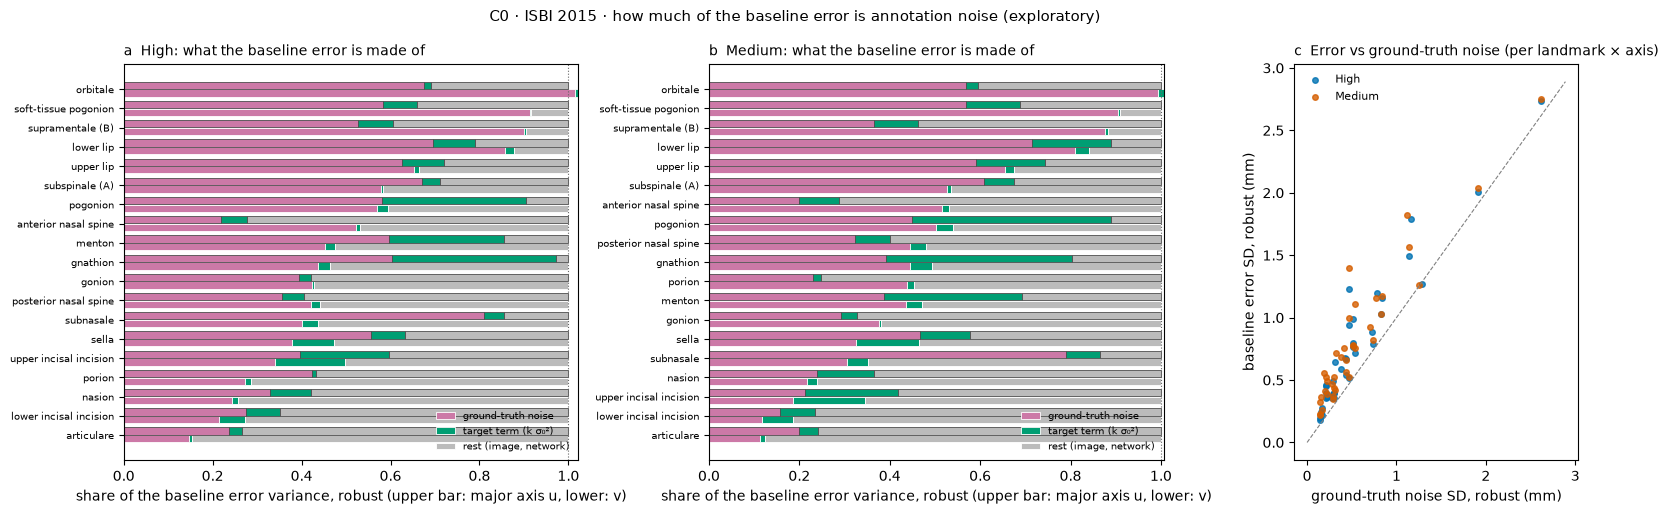

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.6, 1.6, 1]})
for ax, t in zip(axs[:2], TIERS):
    g = SH[SH.tier == t].sort_values(["name", "direction"])
    order = g[g.direction == "u"].sort_values("label_share_robust").name.tolist()
    y = np.arange(len(order))
    for dr, off in (("u", -0.2), ("v", 0.2)):
        h = g[g.direction == dr].set_index("name").reindex(order)
        left = np.zeros(len(order))
        for col, c, lab in (("label_share_robust", "#CC79A7", "ground-truth noise"), ("target_share_robust", "#009E73", "target term (k σ₀²)"),
                            ("rest_share_robust", "#BBBBBB", "rest (image, network)")):
            val = h[col].clip(lower=0).values
            ax.barh(y + off, val, height=0.38, left=left, color=c, edgecolor="white" if dr == "u" else "0.3", lw=0.6,
                    label=lab if dr == "u" else None)
            left += val
    ax.axvline(1, color="0.4", lw=0.8, ls=":")
    ax.set_yticks(y); ax.set_yticklabels(order, fontsize=7)
    ax.set_xlabel("share of the baseline error variance, robust (upper bar: major axis u, lower: v)")
    ax.set_title(f"{'ab'[list(TIERS).index(t)]}  {t}: what the baseline error is made of", loc="left", fontsize=10)
    ax.legend(fontsize=7, frameon=False, loc="lower right")
ax = axs[2]
for t in TIERS:
    g = SH[SH.tier == t]
    ax.scatter(g.gt_noise_sd_robust_mm, g.err_sd_robust_mm, s=16, color=COLORS[t], alpha=0.8, label=t)
lim = [0, max(SH.err_sd_robust_mm.max(), SH.gt_noise_sd_robust_mm.max()) * 1.05]
ax.plot(lim, lim, color="0.5", ls="--", lw=0.8)
ax.set_xlabel("ground-truth noise SD, robust (mm)"); ax.set_ylabel("baseline error SD, robust (mm)")
ax.set_title("c  Error vs ground-truth noise (per landmark × axis)", loc="left", fontsize=10); ax.legend(fontsize=8, frameon=False)
fig.suptitle("C0 · ISBI 2015 · how much of the baseline error is annotation noise (exploratory)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "annotation_noise.png", dpi=150, bbox_inches="tight")